# Eda analisi

* Importo le librerie e mostro il file dopo la merge

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
df_analisi=pd.read_csv(r'Dati\puliti\Unione_dati.csv',sep=';',low_memory=False)
df_analisi.head(10)

,REF_AREA,DATA_TYPE,RESULT,TIME_PERIOD,OBS_VALUE,Codice Ripartizione geografica,Codice Regione,Codice Provincia (Storico),Codice Provincia/Uts,Codice Comune (alfanumerico),...,Comune (dizione straniera),Sigla automobilistica,Capoluogo di Provincia/Uts,Capoluogo di Regione,Popolazione legale,Anno Censimento,Superficie (Kmq),Anno (Superficie),Popolazione residente,Anno (Popolazione residente)
0,1001,KILLINJ,Feriti,2001,10,1.0,1.0,1.0,201.0,1001,...,0,TO,0.0,0.0,2562.0,2021.0,"13,1463",2024.0,2585.0,2024.0
1,1001,KILLINJ,Feriti,2002,10,1.0,1.0,1.0,201.0,1001,...,0,TO,0.0,0.0,2562.0,2021.0,"13,1463",2024.0,2585.0,2024.0
2,1001,KILLINJ,Feriti,2003,7,1.0,1.0,1.0,201.0,1001,...,0,TO,0.0,0.0,2562.0,2021.0,"13,1463",2024.0,2585.0,2024.0
3,1001,KILLINJ,Feriti,2004,13,1.0,1.0,1.0,201.0,1001,...,0,TO,0.0,0.0,2562.0,2021.0,"13,1463",2024.0,2585.0,2024.0
4,1001,KILLINJ,Feriti,2005,2,1.0,1.0,1.0,201.0,1001,...,0,TO,0.0,0.0,2562.0,2021.0,"13,1463",2024.0,2585.0,2024.0
5,1001,KILLINJ,Feriti,2006,1,1.0,1.0,1.0,201.0,1001,...,0,TO,0.0,0.0,2562.0,2021.0,"13,1463",2024.0,2585.0,2024.0
6,1001,KILLINJ,Feriti,2007,12,1.0,1.0,1.0,201.0,1001,...,0,TO,0.0,0.0,2562.0,2021.0,"13,1463",2024.0,2585.0,2024.0
7,1001,KILLINJ,Feriti,2008,10,1.0,1.0,1.0,201.0,1001,...,0,TO,0.0,0.0,2562.0,2021.0,"13,1463",2024.0,2585.0,2024.0
8,1001,KILLINJ,Feriti,2009,7,1.0,1.0,1.0,201.0,1001,...,0,TO,0.0,0.0,2562.0,2021.0,"13,1463",2024.0,2585.0,2024.0
9,1001,KILLINJ,Feriti,2010,14,1.0,1.0,1.0,201.0,1001,...,0,TO,0.0,0.0,2562.0,2021.0,"13,1463",2024.0,2585.0,2024.0


* Vediamo l'andamento negli anni degli incidenti 

<Axes: xlabel='TIME_PERIOD'>

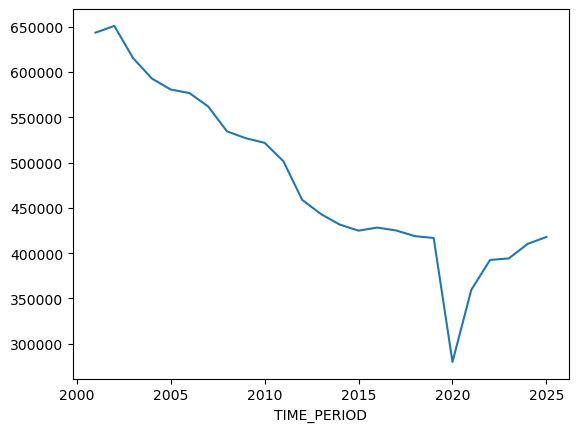

In [2]:
andamento = df_analisi.groupby('TIME_PERIOD')['OBS_VALUE'].sum()
andamento.plot()

* Facendo un po' di ricerche si può notare che l'andamento è in linea con gli interventi fatti nel campo della sicurezza, escluso il calo drastrico nel 2020 a causa del COVID-19, infatti si è visto nel 2003 l'introduzione della patente a punti, nel 2008 la crisi economica e calo invece più nell'arco temporale ad un investimento in termini di sicurezza nelle autovetture con sitemi ABS, frenata assistita e altri e anche un soluzione in termini di sicurezza stradale con l'implemento degli autovelox e dei sistemi  tutor nelle autostrade.

* Vediamo che valori sugli incidenti sono stati visualizzati per ogni anno

In [3]:
lista=df_analisi.groupby('TIME_PERIOD')['OBS_VALUE'].sum()
print(lista)

TIME_PERIOD
2001    643482
2002    650873
2003    615309
2004    592791
2005    580687
2006    576748
2007    561852
2008    534433
2009    526900
2010    521831
2011    501517
2012    458845
2013    443154
2014    431559
2015    424887
2016    428249
2017    425061
2018    418806
2019    416740
2020    279941
2021    359478
2022    392523
2023    394198
2024    410247
2025    417897
Name: OBS_VALUE, dtype: int64


# Analisi sull'anno 2024

* Vediamo che l'info ci riporta il datatype errato su superficie kmq

In [4]:
df_analisi.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 592635 entries, 0 to 592634
Data columns (total 22 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   REF_AREA                        592635 non-null  int64  
 1   DATA_TYPE                       592635 non-null  object 
 2   RESULT                          592635 non-null  object 
 3   TIME_PERIOD                     592635 non-null  int64  
 4   OBS_VALUE                       592635 non-null  int64  
 5   Codice Ripartizione geografica  592635 non-null  float64
 6   Codice Regione                  592635 non-null  float64
 7   Codice Provincia (Storico)      592635 non-null  float64
 8   Codice Provincia/Uts            592635 non-null  float64
 9   Codice Comune (alfanumerico)    592635 non-null  int64  
 10  Codice Comune (numerico)        592635 non-null  float64
 11  Comune                          592635 non-null  object 
 12  Comune (dizione 

* Sistemiamo il datatype nel modo corretto

In [5]:
df_analisi['Superficie (Kmq)'] = pd.to_numeric(df_analisi['Superficie (Kmq)'].str.replace(',', '.'), errors='coerce')
df_analisi['Popolazione residente'] = df_analisi['Popolazione residente'].astype('Int64')

* Controllo

In [6]:
df_analisi.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 592635 entries, 0 to 592634
Data columns (total 22 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   REF_AREA                        592635 non-null  int64  
 1   DATA_TYPE                       592635 non-null  object 
 2   RESULT                          592635 non-null  object 
 3   TIME_PERIOD                     592635 non-null  int64  
 4   OBS_VALUE                       592635 non-null  int64  
 5   Codice Ripartizione geografica  592635 non-null  float64
 6   Codice Regione                  592635 non-null  float64
 7   Codice Provincia (Storico)      592635 non-null  float64
 8   Codice Provincia/Uts            592635 non-null  float64
 9   Codice Comune (alfanumerico)    592635 non-null  int64  
 10  Codice Comune (numerico)        592635 non-null  float64
 11  Comune                          592635 non-null  object 
 12  Comune (dizione 

* Calcoliamo il tasso per 1000 abitanti e per km2

In [7]:
df_analisi = df_analisi[(df_analisi['Superficie (Kmq)'] > 0) & (df_analisi['Popolazione residente'] > 0)]
df_analisi['incidenti_per_Kmq'] = df_analisi['OBS_VALUE'] / df_analisi['Superficie (Kmq)']
df_analisi['incidenti_per_1000_Abitanti'] = (df_analisi['OBS_VALUE'] / df_analisi['Popolazione residente']) * 1000
df_analisi[['TIME_PERIOD', 'Comune', 'OBS_VALUE', 'incidenti_per_Kmq', 'incidenti_per_1000_Abitanti']].head()

,TIME_PERIOD,Comune,OBS_VALUE,incidenti_per_Kmq,incidenti_per_1000_Abitanti
0,2001,Agliè,10,0.760670,3.868472
1,2002,Agliè,10,0.760670,3.868472
2,2003,Agliè,7,0.532469,2.70793
3,2004,Agliè,13,0.988871,5.029014
4,2005,Agliè,2,0.152134,0.773694


* Costruisco un boxplot per vedere la distribuzione dei dati e capire se ci sono outliers

<Axes: >

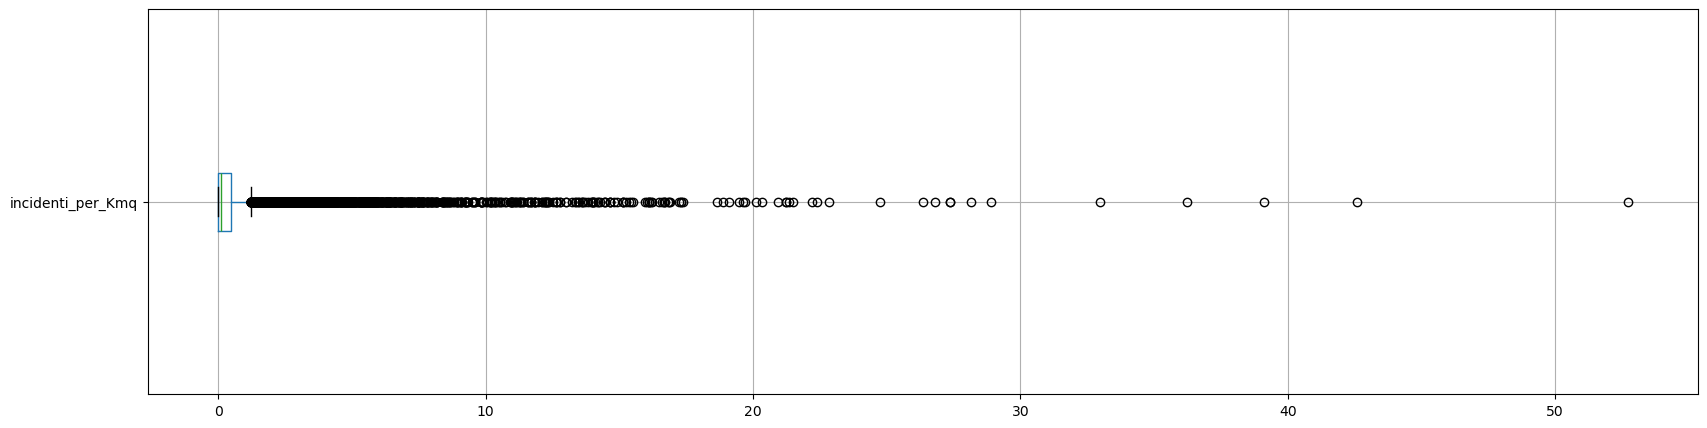

In [8]:
fig = plt.figure(figsize=(20, 5))
df_analisi[df_analisi['TIME_PERIOD'] == 2024].boxplot(column='incidenti_per_Kmq', vert=False)

<Axes: >

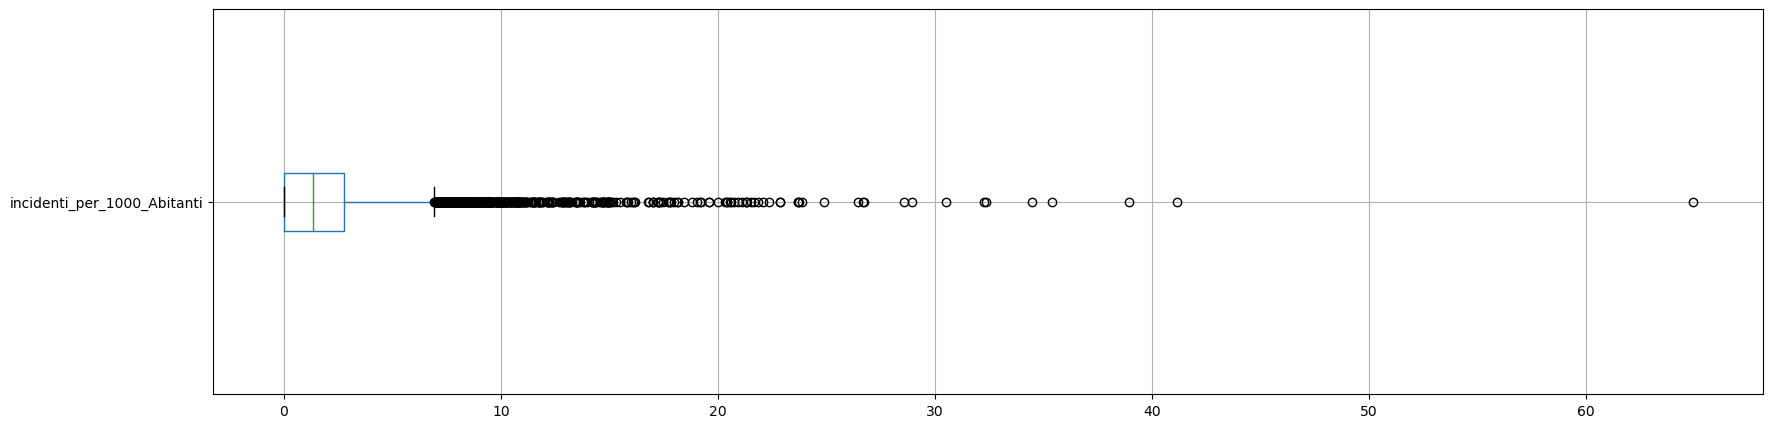

In [9]:
fig = plt.figure(figsize=(20, 5))
df_analisi[df_analisi['TIME_PERIOD'] == 2024].boxplot(column='incidenti_per_1000_Abitanti', vert=False)

* Cerchiamo di esaminare gli outliers e capire se sono dati corretti o se sono errori di inserimento dati, per fare questo vediamo i valori minimi e massimi e i quartili

In [10]:
df_kmq = df_analisi[df_analisi['TIME_PERIOD'] == 2024]
df_kmq['incidenti_per_Kmq'].describe()


count    19014.000000
mean         0.638981
std          1.810252
min          0.000000
25%          0.000000
50%          0.110157
75%          0.484324
max         52.709725
Name: incidenti_per_Kmq, dtype: float64

* Qui si può già notare che città come Milano, torino, Roma e Napoli hanno un tasso di incidenti per km2 molto alto, ma questo è dovuto al fatto che sono città con una popolazione molto alta e quindi anche con un alto numero di incidenti.

In [11]:
df_kmq= df_analisi.sort_values(by='incidenti_per_Kmq', ascending=False)
df_kmq= df_kmq[df_kmq['TIME_PERIOD'] == 2024].drop_duplicates('Comune')
df_kmq[['TIME_PERIOD', 'Comune','incidenti_per_Kmq']].head(10)

,TIME_PERIOD,Comune,incidenti_per_Kmq
132659,2024,Milano,52.709725
130160,2024,Cormano,39.121007
129731,2024,Cinisello Balsamo,36.230745
19844,2024,Torino,32.984920
130364,2024,Corsico,28.885576
388745,2024,Napoli,27.356064
139592,2024,Bergamo,26.787267
322919,2024,Firenze,26.361652
586214,2024,Lissone,24.742623
445685,2024,Bari,21.504480


* Nel caso di incidenti per mille abitatanti mettiamo come valore di partenza città con più di 10000 abitanti in modo che non vengano prese città con pochi abitanti che alzano la media anche con un singolo incidente 

In [12]:
df_1000 = df_analisi[df_analisi['Popolazione residente'] > 10000].copy()
df_1000 = df_1000[df_1000['TIME_PERIOD'] == 2024]
df_1000['incidenti_per_1000_Abitanti'].describe()

count       3603.0
mean      2.110747
std         1.9421
min            0.0
25%        0.07827
50%       2.005383
75%       3.368422
max      10.754427
Name: incidenti_per_1000_Abitanti, dtype: Float64

* Notiamo che i comuni con un tasso alto sono principalmente località turistiche di mare, quindi con una popolazione residente bassa ma con un alto afflusso di turisti, che quindi alzano il tasso di incidenti per 1000 abitanti.

In [13]:
df_1000 = df_analisi[(df_analisi['TIME_PERIOD'] == 2024) & (df_analisi['Popolazione residente'] > 10000)]
df_1000 = df_1000.sort_values(by='incidenti_per_1000_Abitanti', ascending=False)
df_1000[['TIME_PERIOD','Popolazione residente', 'Comune', 'incidenti_per_1000_Abitanti']].head(10)


,TIME_PERIOD,Popolazione residente,Comune,incidenti_per_1000_Abitanti
93443,2024,12367,Lavagna,10.754427
167783,2024,13540,Rezzato,10.487445
88421,2024,11012,Finale Ligure,10.170723
322205,2024,17994,Calenzano,9.94776
86411,2024,23539,Albenga,9.346191
322001,2024,10939,Barberino di Mugello,9.324436
226397,2024,10899,Peschiera del Garda,9.083402
251585,2024,26994,Jesolo,9.002
402551,2024,22410,Capaccio Paestum,8.96921
139592,2024,120389,Bergamo,8.954306


* Infatti vediamo che togliendo il filtro sui 10000 il valore di incidenti per 1000 abitanti si innalza notevolmente (i comuni sotto elencati hanno una popolazione tra 58-492 abitanti)

In [14]:
df_basso = df_analisi.sort_values(by='incidenti_per_1000_Abitanti', ascending=False)
df_basso = df_basso[df_basso['TIME_PERIOD'] == 2024].drop_duplicates('Comune')
df_basso[['TIME_PERIOD','Popolazione residente', 'Comune', 'incidenti_per_1000_Abitanti']].head(10)

,TIME_PERIOD,Popolazione residente,Comune,incidenti_per_1000_Abitanti
36131,2024,77,Argentera,64.935065
239180,2024,340,Colle Santa Lucia,41.176471
23480,2024,113,Balmuccia,35.39823
44321,2024,58,Marmora,34.482759
29033,2024,371,Villarboit,32.345013
47285,2024,186,Paroldo,32.258065
63278,2024,492,Belforte Monferrato,30.487805
110567,2024,311,Brienno,28.938907
414110,2024,70,Carapelle Calvisio,28.571429
26855,2024,187,Piode,26.737968


* Creiamo un grafico a dispersione per visualizzare la relazione tra il numero di incidenti per km2 e il numero di incidenti per 1000 abitanti. Questo ci aiuterà a capire se esiste una correlazione tra le due variabili.

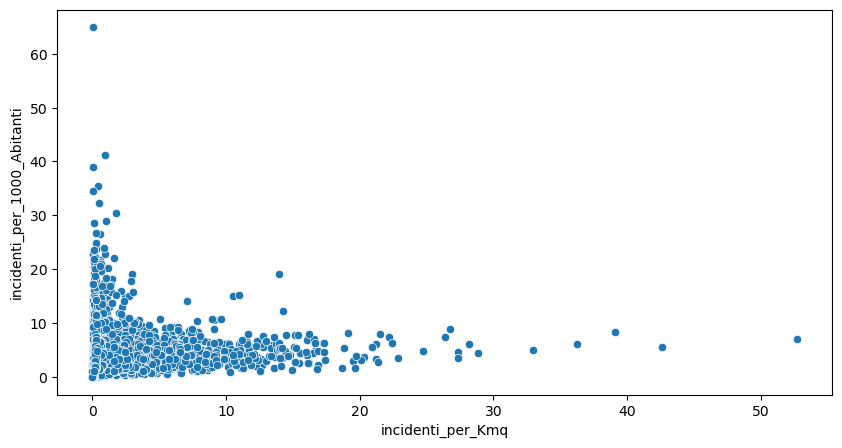

In [15]:
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df_analisi[df_analisi['TIME_PERIOD'] == 2024], x='incidenti_per_Kmq', y='incidenti_per_1000_Abitanti') 
plt.show()
